In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
mergin_cleaned_df = pd.read_csv('F:\Economic2019\Ookla_Viirs_preprocessed.csv')
mergin_cleaned_df.head()

<>:1: SyntaxWarning: invalid escape sequence '\E'
<>:1: SyntaxWarning: invalid escape sequence '\E'
C:\Users\Omar\AppData\Local\Temp\ipykernel_16212\2728787016.py:1: SyntaxWarning: invalid escape sequence '\E'
  mergin_cleaned_df = pd.read_csv('F:\Economic2019\Ookla_Viirs_preprocessed.csv')


,longitude,latitude,light_intensity,geometry,index_right,avg_d_kbps,avg_u_kbps,avg_lat_ms,tests,devices
0,-53.087500,-22.662500,0.009948,POINT (-53.0874999447 -22.6625001813),8380836,2554.0,2.0,28.0,2,1
1,-53.079167,-22.654167,0.001441,POINT (-53.0791666113 -22.6541668479),8380938,4846.5,507.0,34.5,1,1
2,-53.079167,-22.650000,0.001429,POINT (-53.0791666113 -22.6500001812),8380938,4846.5,507.0,34.5,1,1
3,-53.079167,-22.616667,0.001418,POINT (-53.0791666113 -22.6166668476),8380935,5534.0,18846.0,29.0,1,1
4,-53.075000,-22.654167,0.001453,POINT (-53.0749999446 -22.6541668479),8380938,4846.5,507.0,34.5,1,1


In [3]:
mergin_cleaned_df['light_intensity'].describe()

count    166499.000000
mean          0.098270
std           0.131481
min           0.000567
25%           0.008035
50%           0.040069
75%           0.139401
max           2.154016
Name: light_intensity, dtype: float64

In [4]:
mergin_cleaned_df['avg_d_kbps'].describe()

count    166499.000000
mean       8071.582974
std        6329.026034
min           1.000000
25%        3030.062500
50%        6433.000000
75%       11527.111111
max       29998.750000
Name: avg_d_kbps, dtype: float64

1.	Heatmap

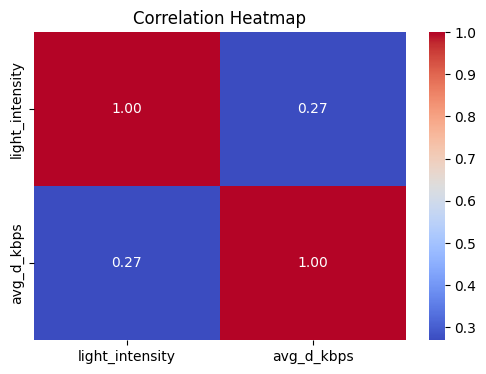

In [5]:
correlation_matrix = mergin_cleaned_df[['light_intensity', 'avg_d_kbps']].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Correlation Heatmap")
plt.show()

2.	Scatter Plot

Text(0, 0.5, 'light_intensity')

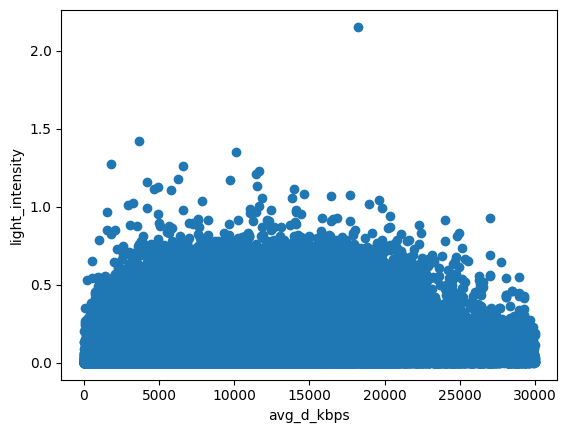

In [6]:
plt.scatter(data = mergin_cleaned_df, x = 'avg_d_kbps', y = 'light_intensity')
plt.xlabel('avg_d_kbps')
plt.ylabel('light_intensity')

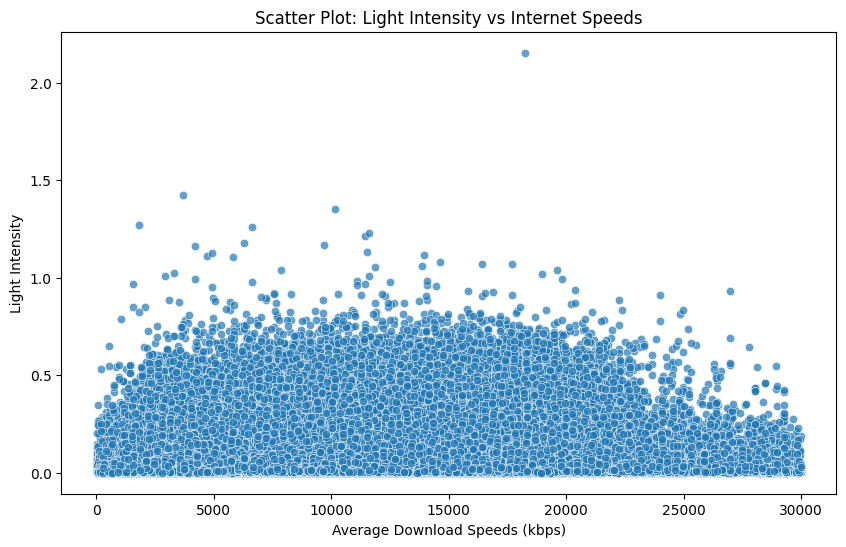

In [7]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=mergin_cleaned_df,
    x='avg_d_kbps',
    y='light_intensity',
    alpha=0.7
)
plt.title("Scatter Plot: Light Intensity vs Internet Speeds")
plt.xlabel("Average Download Speeds (kbps)")
plt.ylabel("Light Intensity")
plt.show()

3.	Bar Chart

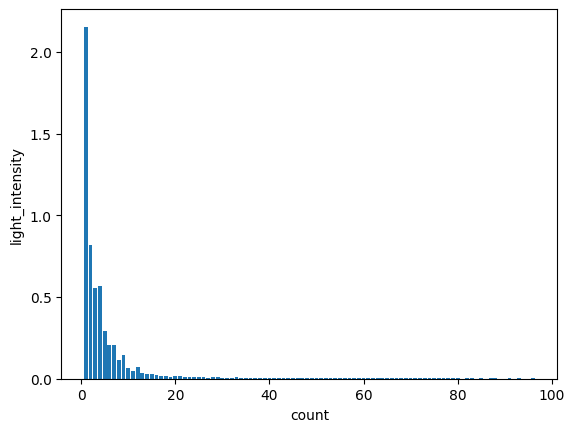

In [8]:
x = mergin_cleaned_df['light_intensity'].value_counts(sort=False)
y = mergin_cleaned_df['light_intensity'].value_counts(sort=False).index

plt.bar(x, y)
plt.xlabel('count')
plt.ylabel('light_intensity')
plt.show()

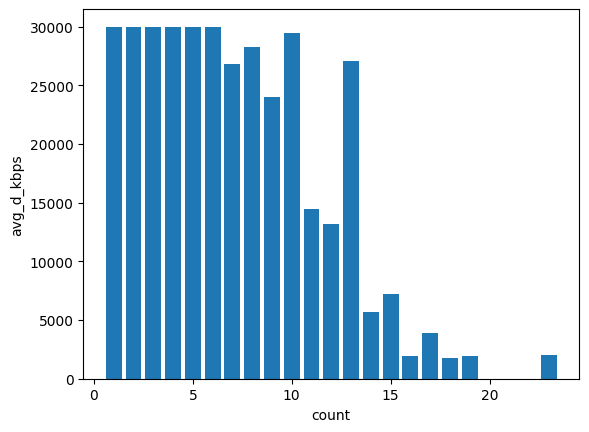

In [49]:
x = mergin_cleaned_df['avg_d_kbps'].value_counts(sort=False)
y = mergin_cleaned_df['avg_d_kbps'].value_counts(sort=False).index

plt.bar(x, y)
plt.xlabel('count')
plt.ylabel('avg_d_kbps')
plt.show()

In [9]:
# # Extract two decimals for longitude and latitude
# mergin_cleaned_df['longitude'] = mergin_cleaned_df['longitude'].round(2)
# mergin_cleaned_df['latitude'] = mergin_cleaned_df['latitude'].round(2)

# # Find the top 5 regions by light intensity
# top_regions = mergin_cleaned_df.nlargest(5, 'light_intensity')

# # Create a new column for unique labels combining state and coordinates
# top_regions['region_label'] = top_regions['state'] + ' (' + top_regions['longitude'].astype(str) + ', ' + top_regions['latitude'].astype(str) + ')'

# # Plot with the new region labels on the x-axis
# plt.figure(figsize=(12, 6))
# sns.barplot(
#     data=top_regions,
#     x='region_label',  # Use the unique labels for the x-axis
#     y='light_intensity',
#     palette='coolwarm',
# )
# plt.title("Top 5 Regions by Radiance Change")
# plt.xlabel("Region (State and Coordinates)")
# plt.ylabel("Light Intensity")
# plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
# plt.show()


In [10]:
# # Extract two decimals for longitude and latitude
# mergin_cleaned_df['longitude'] = mergin_cleaned_df['longitude'].round(2)
# mergin_cleaned_df['latitude'] = mergin_cleaned_df['latitude'].round(2)

# # Find the top 5 regions by light intensity
# top_regions = mergin_cleaned_df.nlargest(10, 'avg_d_kbps')

# # Create a new column for unique labels combining state and coordinates
# top_regions['region_label'] = top_regions['state'] + ' (' + top_regions['longitude'].astype(str) + ', ' + top_regions['latitude'].astype(str) + ')'

# # Plot with the new region labels on the x-axis
# plt.figure(figsize=(12, 6))
# sns.barplot(
#     data=top_regions,
#     x='region_label',  # Use the unique labels for the x-axis
#     y='avg_d_kbps',
#     palette='coolwarm',
# )
# plt.title("Top 5 Regions by Internet Speed")
# plt.xlabel("Region (State and Coordinates)")
# plt.ylabel("Light Intensity")
# plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
# plt.show()


4.	Geospatial Overlay

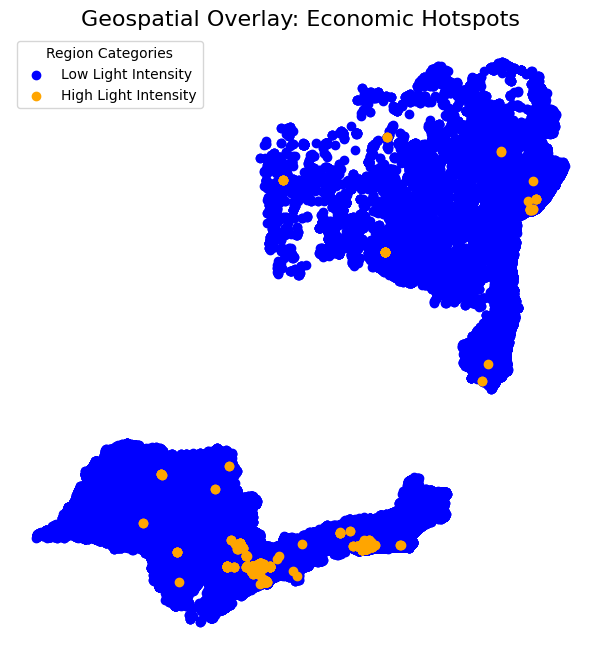

In [18]:
mergin_cleaned_df['geometry'] = gpd.points_from_xy(mergin_cleaned_df['longitude'], mergin_cleaned_df['latitude'])
gdf = gpd.GeoDataFrame(mergin_cleaned_df, geometry='geometry')

def classify_region(row):
    if row['light_intensity'] > 0.6:
        return 'High Light Intensity'
    else:
        return 'Low Light Intensity'

gdf['region_category'] = gdf.apply(classify_region, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

categories = {
    'Low Light Intensity': 'blue',
    'High Light Intensity': 'orange',
}

for category, color in categories.items():
    subset = gdf[gdf['region_category'] == category]
    subset.plot(ax=ax, color=color, label=category)

plt.legend(title="Region Categories")
plt.title("Geospatial Overlay: Economic Hotspots", fontsize=16)
plt.axis('off')
plt.show()

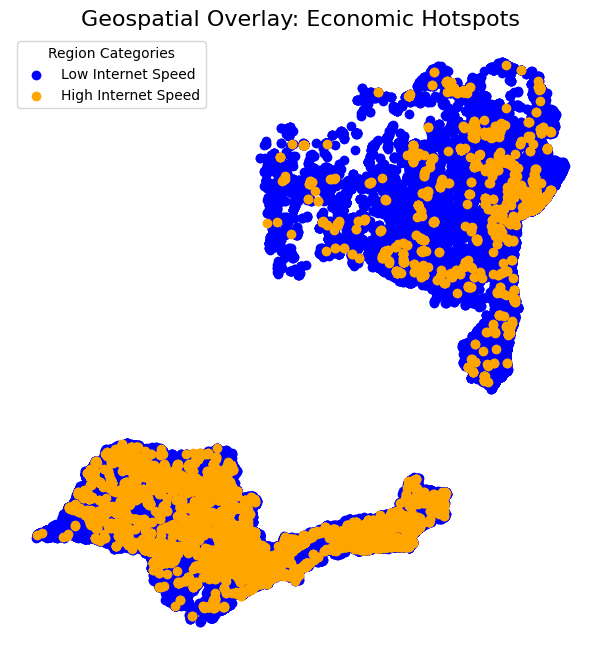

In [19]:
mergin_cleaned_df['geometry'] = gpd.points_from_xy(mergin_cleaned_df['longitude'], mergin_cleaned_df['latitude'])
gdf = gpd.GeoDataFrame(mergin_cleaned_df, geometry='geometry')

def classify_region(row):
    if row['avg_d_kbps'] > 20000:
        return 'High Internet Speed'
    else:
        return 'Low Internet Speed'

gdf['region_category'] = gdf.apply(classify_region, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

categories = {
    'Low Internet Speed': 'blue',
    'High Internet Speed': 'orange',
}

for category, color in categories.items():
    subset = gdf[gdf['region_category'] == category]
    subset.plot(ax=ax, color=color, label=category)

plt.legend(title="Region Categories")
plt.title("Geospatial Overlay: Economic Hotspots", fontsize=16)
plt.axis('off')
plt.show()


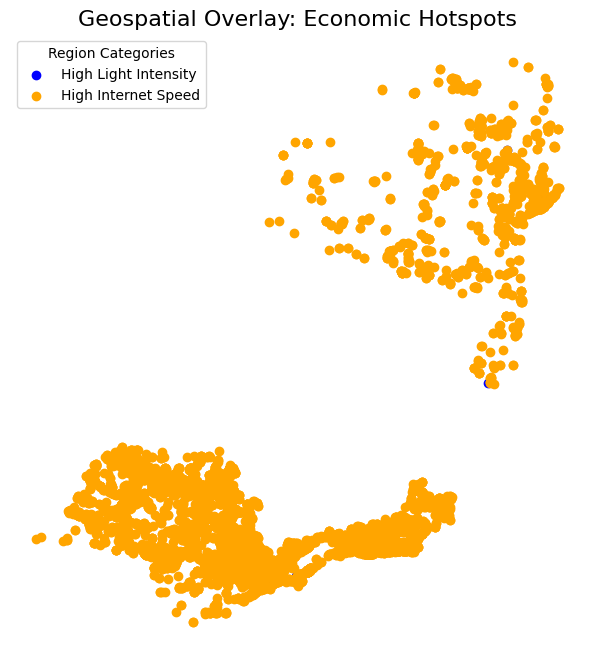

In [ ]:
mergin_cleaned_df['geometry'] = gpd.points_from_xy(mergin_cleaned_df['longitude'], mergin_cleaned_df['latitude'])
gdf = gpd.GeoDataFrame(mergin_cleaned_df, geometry='geometry')

def classify_region(row):
    if row['light_intensity'] >= 0.6:
        return 'High Light Intensity'
    elif row['avg_d_kbps'] >= 20000:
        return 'High Internet Speed'

gdf['region_category'] = gdf.apply(classify_region, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

categories = {
    'High Light Intensity': 'blue',
    'High Internet Speed': 'orange',
}

for category, color in categories.items():
    subset = gdf[gdf['region_category'] == category]
    subset.plot(ax=ax, color=color, label=category)

plt.legend(title="Region Categories")
plt.title("Geospatial Overlay: Economic Hotspots", fontsize=16)
plt.axis('off')
plt.show()


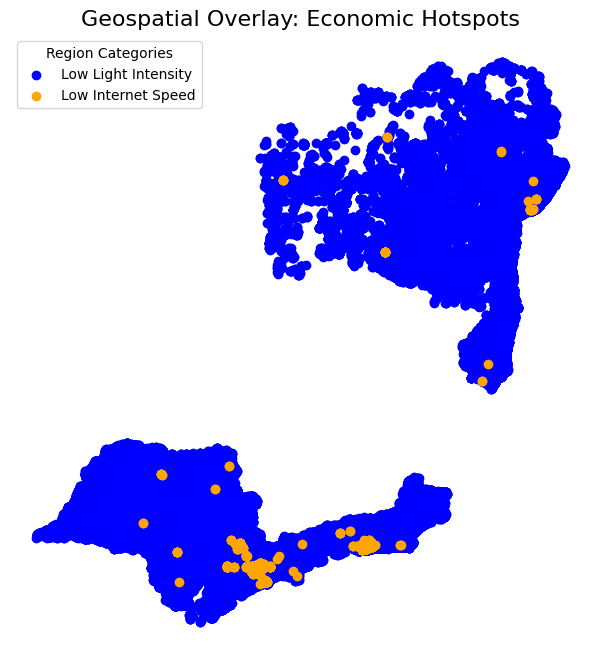

In [20]:
mergin_cleaned_df['geometry'] = gpd.points_from_xy(mergin_cleaned_df['longitude'], mergin_cleaned_df['latitude'])
gdf = gpd.GeoDataFrame(mergin_cleaned_df, geometry='geometry')

def classify_region(row):
    if row['light_intensity'] < 0.6:
        return 'Low Light Intensity'
    elif row['avg_d_kbps'] < 20000:
        return 'Low Internet Speed'

gdf['region_category'] = gdf.apply(classify_region, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

categories = {
    'Low Light Intensity': 'blue',
    'Low Internet Speed': 'orange',
}

for category, color in categories.items():
    subset = gdf[gdf['region_category'] == category]
    subset.plot(ax=ax, color=color, label=category)

plt.legend(title="Region Categories")
plt.title("Geospatial Overlay: Economic Hotspots", fontsize=16)
plt.axis('off')
plt.show()


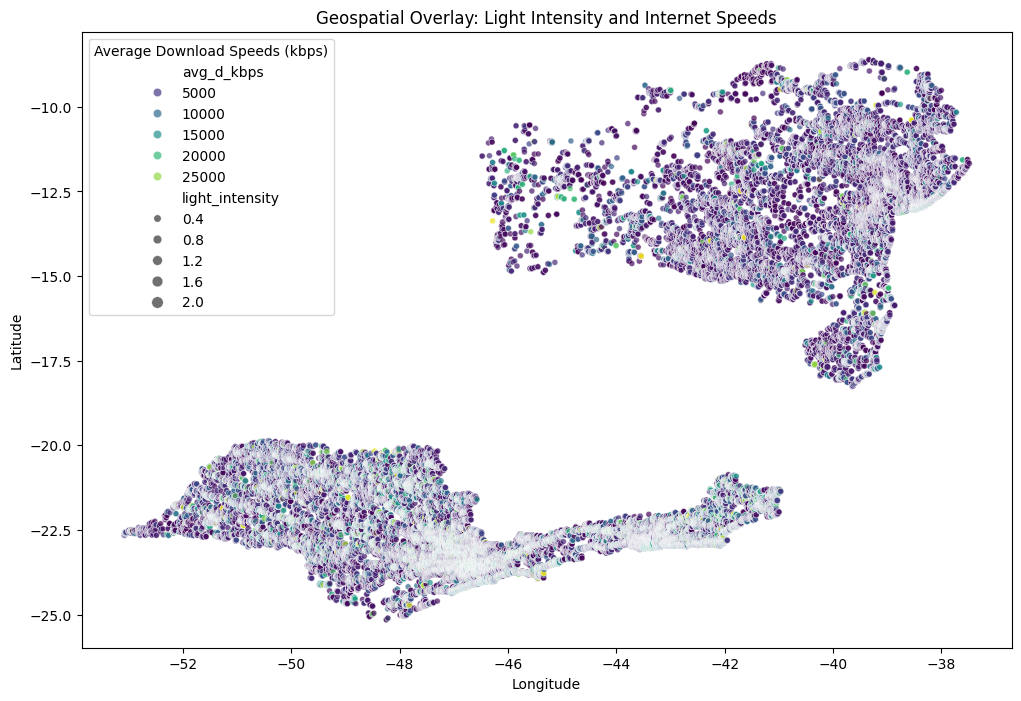

In [17]:
# 2. Geospatial overlay (Scatter plot on longitude and latitude)
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=mergin_cleaned_df,
    x='longitude',
    y='latitude',
    size='light_intensity',
    hue='avg_d_kbps',
    palette='viridis',
    alpha=0.7
)
plt.title("Geospatial Overlay: Light Intensity and Internet Speeds")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Average Download Speeds (kbps)")
plt.show()

5.	Line Chart

In [27]:
# plt.figure(figsize=(12, 6))

# plt.plot(mergin_cleaned_df.index, mergin_cleaned_df['light_intensity'], label='Light Intensity', color='blue', marker='o')
# plt.plot(mergin_cleaned_df.index, mergin_cleaned_df['avg_d_kbps'], label='Average Download Speed (Kbps)', color='orange', marker='s')

# plt.title("Trends: Radiance and Internet Speeds", fontsize=16)
# plt.xlabel("Index", fontsize=12)
# plt.ylabel("Value", fontsize=12)
# plt.grid(True)
# plt.legend()

# plt.tight_layout()
# plt.show()

In [28]:
# # 5. Aggregated Trends: Radiance and Internet Speeds by Region
# mergin_cleaned_df['region'] = (
#     mergin_cleaned_df['latitude'].round(1).astype(str) + ", " +
#     mergin_cleaned_df['longitude'].round(1).astype(str)
# )

# aggregated_data = mergin_cleaned_df.groupby(['region']).agg({
#     'light_intensity': 'mean',
#     'avg_d_kbps': 'mean'
# }).reset_index()

# plt.figure(figsize=(12, 6))
# plt.plot(aggregated_data['region'], aggregated_data['light_intensity'], label="Mean Radiance Change", marker="o")
# plt.plot(aggregated_data['region'], aggregated_data['avg_d_kbps'], label="Mean Download Speed (kbps)", linestyle="--", marker="x")
# plt.xticks(rotation=90, fontsize=8)
# plt.title("Aggregated Trends: Radiance and Internet Speeds by Region")
# plt.xlabel("Region (Latitude, Longitude)")
# plt.ylabel("Values")
# plt.legend()
# plt.tight_layout()
# plt.show()

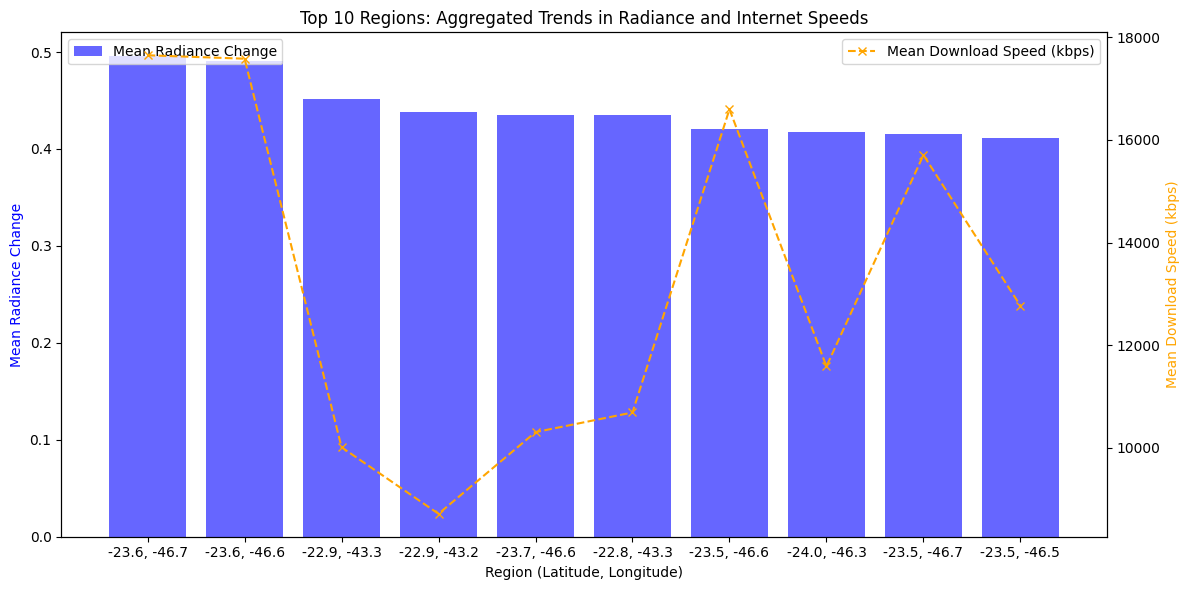

In [21]:
# 5. Improved Aggregated Trends: Top 20 Regions by Radiance and Speeds
mergin_cleaned_df['region'] = (
    mergin_cleaned_df['latitude'].round(1).astype(str) + ", " +
    mergin_cleaned_df['longitude'].round(1).astype(str)
)

aggregated_data = mergin_cleaned_df.groupby(['region']).agg({
    'light_intensity': 'mean',
    'avg_d_kbps': 'mean'
}).reset_index()

top_10_regions = aggregated_data.nlargest(10, 'light_intensity')

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

ax1.bar(top_10_regions['region'], top_10_regions['light_intensity'], color='b', alpha=0.6, label="Mean Radiance Change")
ax2.plot(top_10_regions['region'], top_10_regions['avg_d_kbps'], color='orange', linestyle="--", marker="x", label="Mean Download Speed (kbps)")

ax1.set_xlabel("Region (Latitude, Longitude)", fontsize=10)
ax1.set_ylabel("Mean Radiance Change", color='b', fontsize=10)
ax2.set_ylabel("Mean Download Speed (kbps)", color='orange', fontsize=10)
plt.xticks(rotation=90, fontsize=8)
plt.title("Top 10 Regions: Aggregated Trends in Radiance and Internet Speeds")
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()